**M.Tech (DSE) · Machine Learning · Assignment 2**

# Predicting purchases from online shopping sessions

I compare five classifiers on a practical question. Given the browsing activity recorded during a session, how well can I distinguish visits that end in a purchase from those that do not? I count a completed purchase as the positive class.

I use **purchase F1** to choose between models because I care about two kinds of error. A missed buyer reduces recall. A false purchase alert reduces precision. I also report accuracy, ROC AUC and Matthews correlation coefficient (MCC) to show aspects of performance that F1 does not capture.

## 1. Data source and project setup

I use C. Sakar and Y. Kastro’s *Online Shoppers Purchasing Intention Dataset*. Each row represents one visit to an e-commerce website. I read the original CSV from `data/` and verify its SHA-256 checksum before analysis. The source is included so I can reproduce the experiment without a download. I keep the fitted models and evaluation outputs in separate folders. [UCI dataset](https://doi.org/10.24432/C5F88Q)

In [1]:
from pathlib import Path
from importlib.metadata import version
import hashlib
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, f1_score,
    matthews_corrcoef, precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

SEED = 42
TARGET = "Revenue"
filename = "online_shoppers_intention.csv"
root = Path.cwd()
if root.name == "model":
    root = root.parent
data_path = root / "data" / filename
expected_sha256 = "b3055ee355f59134d851d32641183cb4a8b45def7124d2f50442a042f358e0d9"
if not data_path.is_file():
    raise FileNotFoundError("Run this notebook from the repository root or model folder.")
if hashlib.sha256(data_path.read_bytes()).hexdigest() != expected_sha256:
    raise ValueError("Source CSV does not match the documented UCI dataset checksum.")

model_dir = root / "model"
results_dir = root / "results"
model_dir.mkdir(exist_ok=True)
results_dir.mkdir(exist_ok=True)
print("Dataset file:", filename)

sys.path.insert(0, str(root / "scripts"))
from notebook_tables import display_table
from notebook_visuals import (
    class_balance_figure, comparison_figure, confusion_figure, roc_figure,
    landscape_3d_figure, confusion_3d_figure, precision_recall_figure,
)

def show_figure(fig, filename):
    """Keep a sharp static copy for both the notebook and repository preview."""
    fig.savefig(results_dir / filename, dpi=170, bbox_inches="tight",
                facecolor=fig.get_facecolor())
    plt.show()
    plt.close(fig)


Dataset file: online_shoppers_intention.csv


## 2. Dataset profile

I use 17 predictors drawn from page visits, visit durations, traffic characteristics and visitor context. The target, `Revenue`, records whether a session ends in a transaction. I encode a purchase as 1 and a nonpurchase as 0. I count each outcome before training because the two classes occur at different rates.

12,330 sessions | 17 input features | 0 missing values


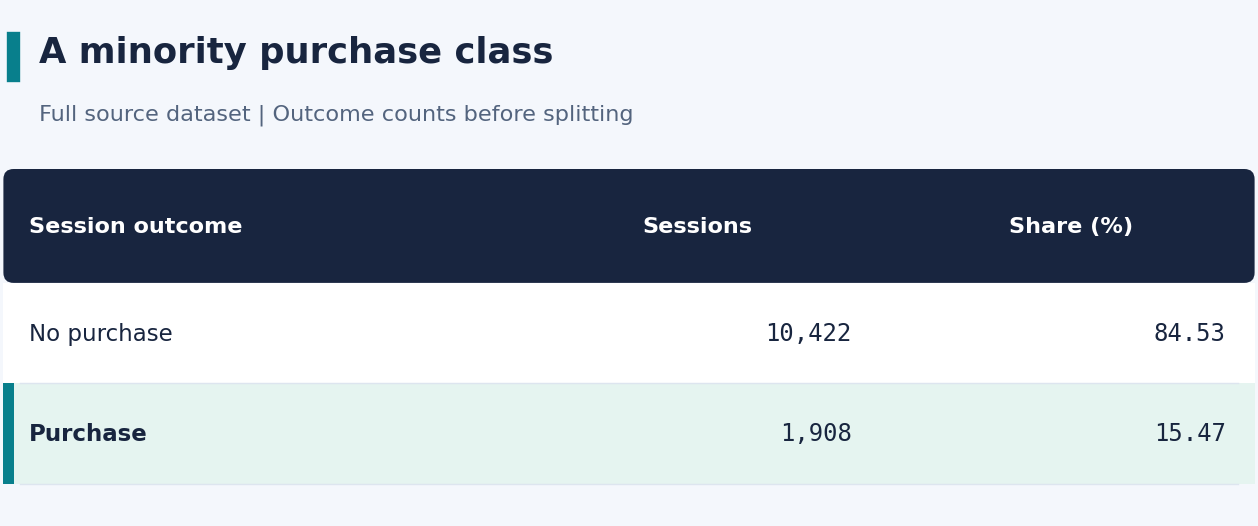

Session outcome,Sessions,Share (%)
No purchase,"10,422",84.53
Purchase,"1,908",15.47


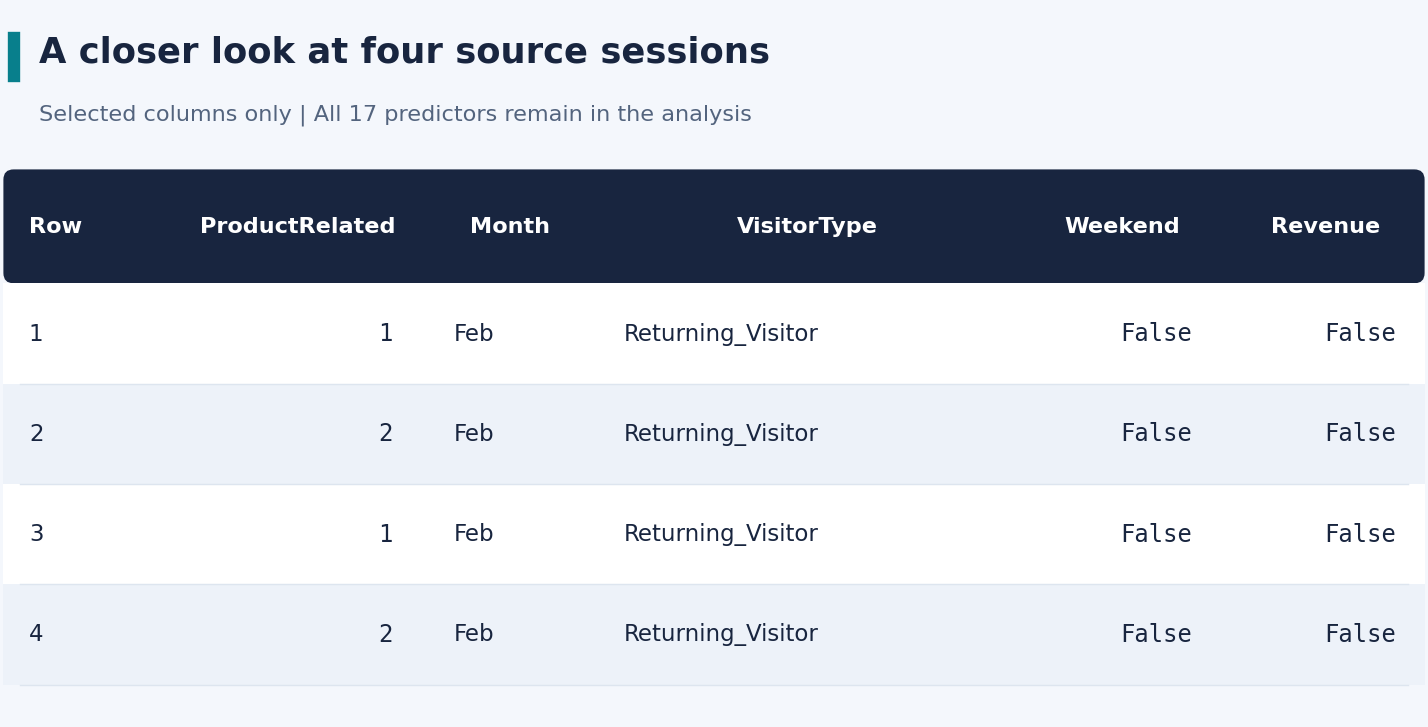

Row,ProductRelated,Month,VisitorType,Weekend,Revenue
1,1,Feb,Returning_Visitor,False,False
2,2,Feb,Returning_Visitor,False,False
3,1,Feb,Returning_Visitor,False,False
4,2,Feb,Returning_Visitor,False,False


Exact duplicate rows retained: 125


In [2]:
data = pd.read_csv(data_path)
numeric = [
    "Administrative", "Administrative_Duration", "Informational",
    "Informational_Duration", "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "PageValues", "SpecialDay",
]
categorical = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend",
]

expected = numeric + categorical + [TARGET]
if set(data.columns) != set(expected):
    raise ValueError(f"Unexpected CSV schema. Expected columns: {expected}")
if data.isna().any().any():
    raise ValueError("The input contains missing values. The original UCI dataset is complete.")

def purchase_labels(values):
    labels = values.astype(str).str.strip().str.lower().map({"true": 1, "false": 0})
    if labels.isna().any():
        raise ValueError("Revenue must contain True or False for each session.")
    return labels.astype(int)

labels = purchase_labels(data[TARGET])
counts = labels.value_counts().reindex([0, 1], fill_value=0)
profile = pd.DataFrame({
    "Sessions": counts,
    "Share (%)": (100 * counts / len(data)).round(2),
})
profile.index = ["No purchase", "Purchase"]
print(f"{len(data):,} sessions | {len(data.columns) - 1} input features | "
      f"{data.isna().sum().sum()} missing values")
display_table(
    profile, "A minority purchase class", "Full source dataset | Outcome counts before splitting",
    formats={"Sessions": ",.0f", "Share (%)": ".2f"},
    widths=[3.0, 2.2, 2.2], index_label="Session outcome", accent_row="Purchase",
)
preview = data[["ProductRelated", "Month", "VisitorType", "Weekend", TARGET]].head(4).copy()
preview.index = preview.index + 1
display_table(preview, "A closer look at four source sessions",
              "Selected columns only | All 17 predictors remain in the analysis",
              widths=[1.0, 1.5, 1.0, 2.5, 1.2, 1.2], index_label="Row")
print("Exact duplicate rows retained:", int(data.duplicated().sum()))


Of the 12,330 sessions, 1,908 end in a purchase, about 15 in every 100 visits. I therefore report how many buyers each model identifies alongside the percentage of all sessions it classifies correctly.

### Seeing the class imbalance

I show both class counts and shares before comparing models. A high overall accuracy is easier to achieve when nonpurchase sessions dominate, so I keep purchase detection visible throughout the analysis.

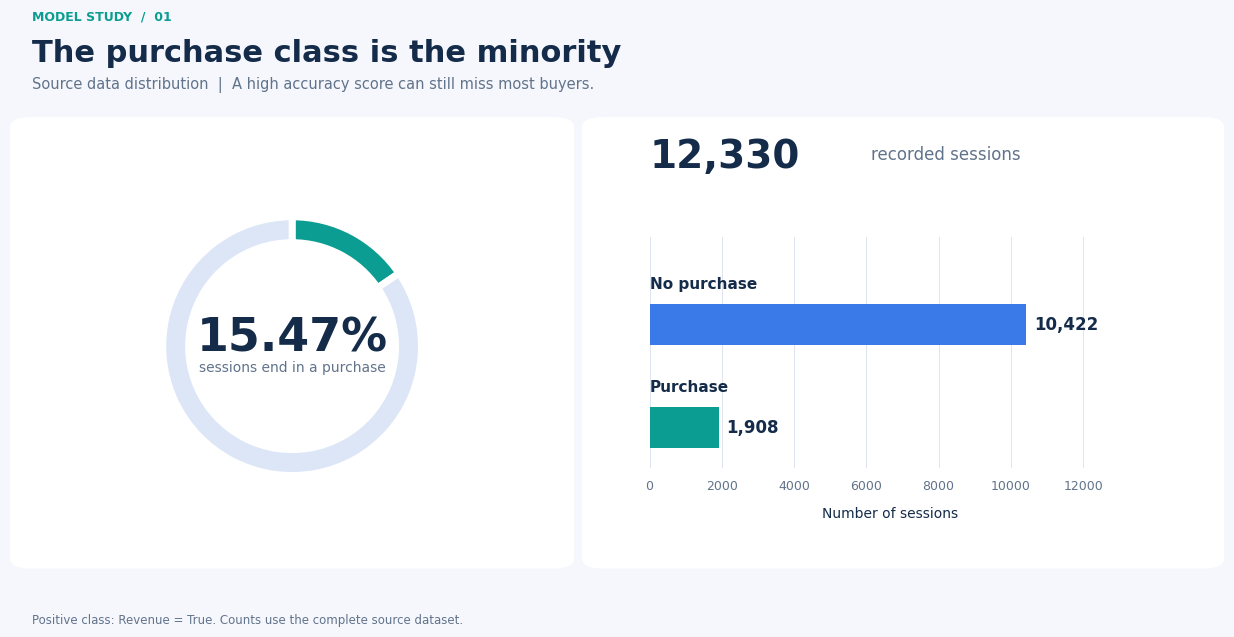

In [3]:
fig = class_balance_figure(counts)
show_figure(fig, "class_balance.png")

## 3. Training and test split

I reserve 20% of the sessions for testing and train on the other 80%. I stratify the split by `Revenue` and set the random seed to 42 so that all five models are evaluated on the same rows. I keep the true outcome in the exported CSV files for evaluation and exclude it from the model inputs.

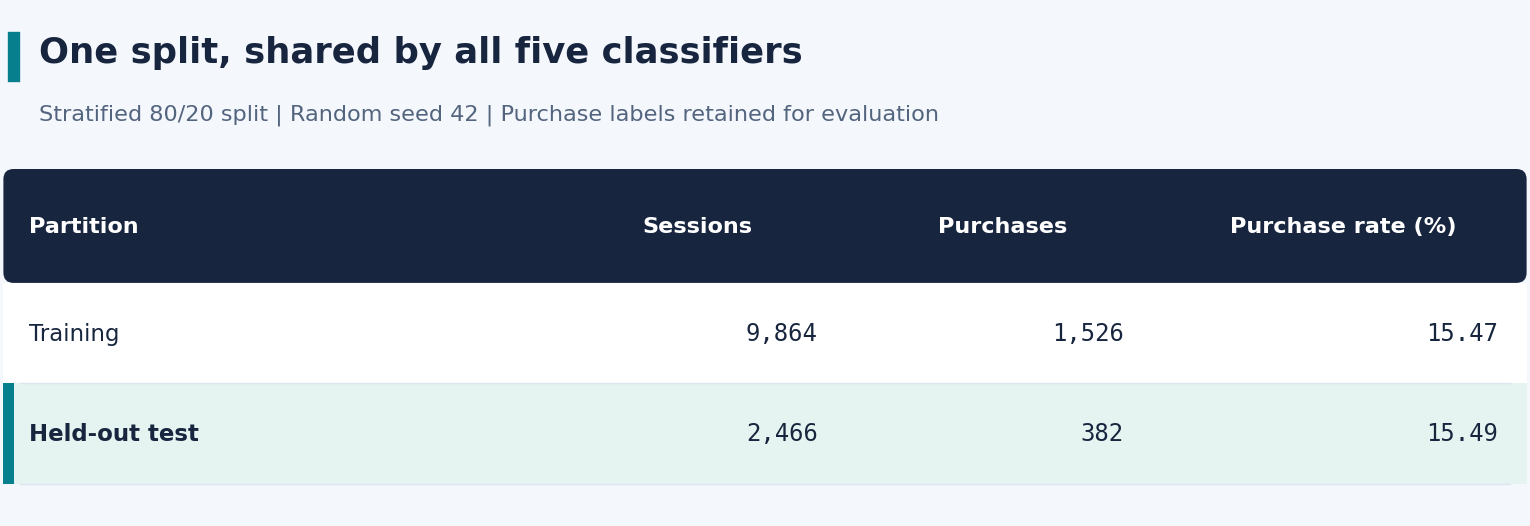

Partition,Sessions,Purchases,Purchase rate (%)
Training,"9,864","1,526",15.47
Held-out test,"2,466",382,15.49


Always predicting no purchase would give 84.51% test accuracy and 0% purchase recall.


In [4]:
train, test = train_test_split(
    data, test_size=0.20, stratify=data[TARGET], random_state=SEED
)
assert train.index.intersection(test.index).empty
assert len(train) + len(test) == len(data)

train.to_csv(root / "train_data.csv", index=False)
test.to_csv(root / "test_data.csv", index=False)
X_train = train.drop(columns=TARGET)
X_test = test.drop(columns=TARGET)
y_train = purchase_labels(train[TARGET])
y_test = purchase_labels(test[TARGET])

split_summary = pd.DataFrame(
    [
        [len(train), int(y_train.sum()), round(100 * y_train.mean(), 2)],
        [len(test), int(y_test.sum()), round(100 * y_test.mean(), 2)],
    ],
    columns=["Sessions", "Purchases", "Purchase rate (%)"],
    index=["Training", "Held-out test"],
)
display_table(
    split_summary, "One split, shared by all five classifiers",
    "Stratified 80/20 split | Random seed 42 | Purchase labels retained for evaluation",
    formats={"Sessions": ",.0f", "Purchases": ",.0f", "Purchase rate (%)": ".2f"},
    widths=[3.2, 1.8, 1.8, 2.2], index_label="Partition", accent_row="Held-out test",
)
print(f"Always predicting no purchase would give {(y_test == 0).mean():.2%} "
      "test accuracy and 0% purchase recall.")

## 4. Preprocessing and model choices

I standardize the ten numeric inputs so that long durations do not dominate distance calculations. I one-hot encode seven categorical inputs, including browser and region. Their numbers identify categories and have no meaningful numerical spacing. For each classifier, I fit the scaler and encoder only on the training rows.

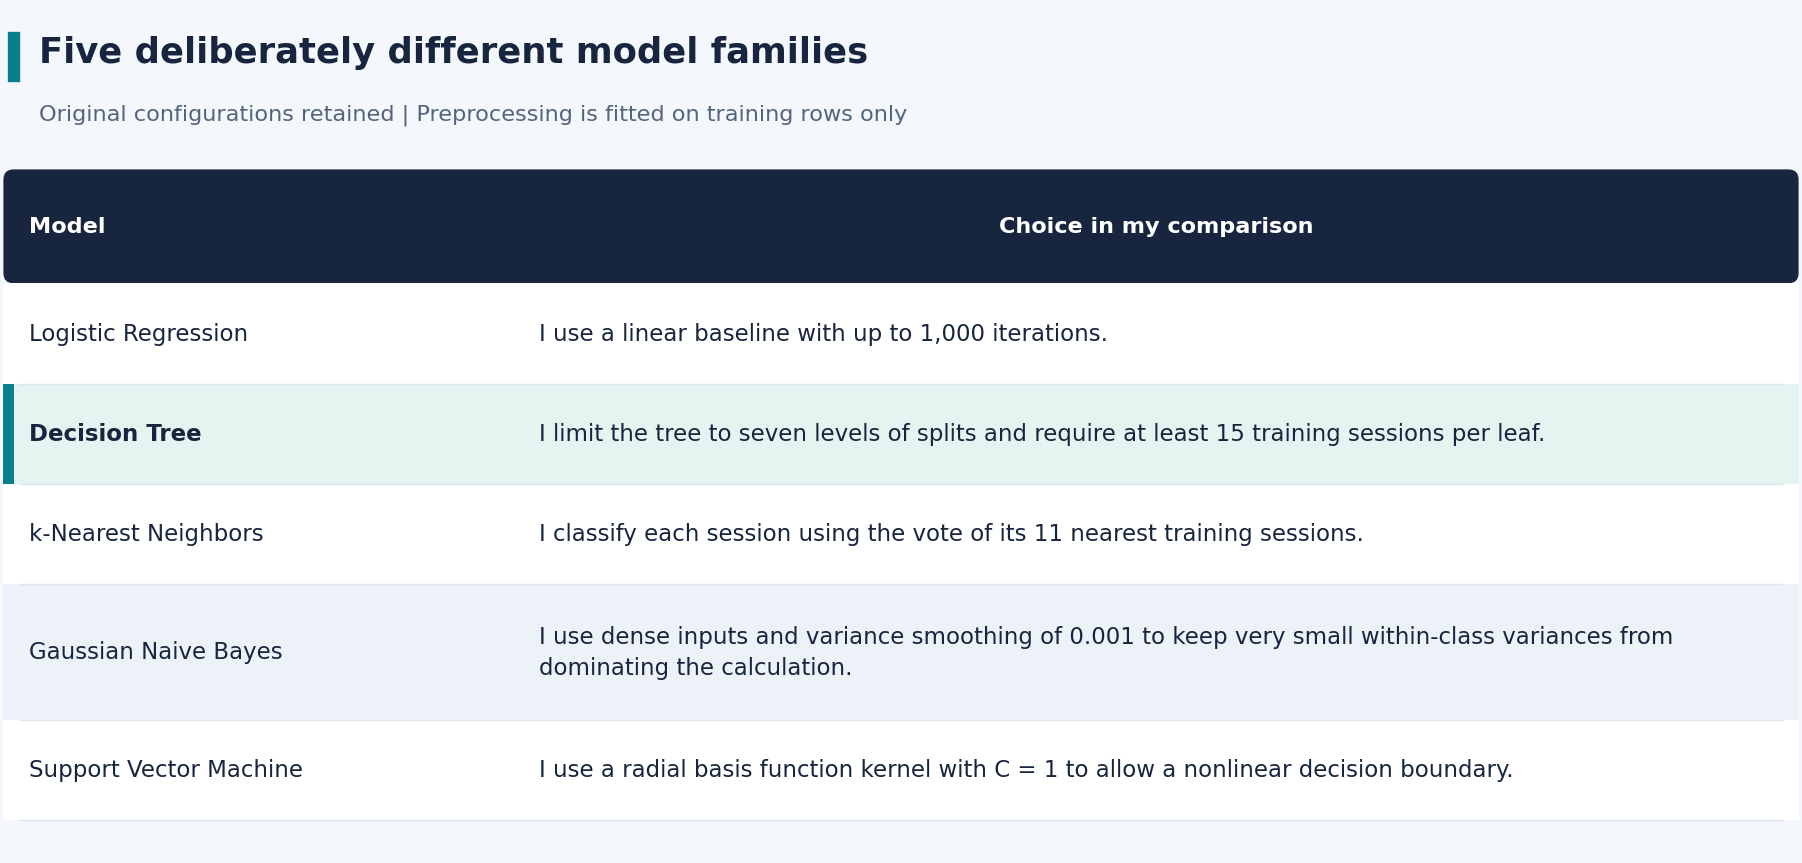

Model,Choice in my comparison
Logistic Regression,"I use a linear baseline with up to 1,000 iterations."
Decision Tree,I limit the tree to seven levels of splits and require at least 15 training sessions per leaf.
k-Nearest Neighbors,I classify each session using the vote of its 11 nearest training sessions.
Gaussian Naive Bayes,I use dense inputs and variance smoothing of 0.001 to keep very small within-class variances from dominating the calculation.
Support Vector Machine,I use a radial basis function kernel with C = 1 to allow a nonlinear decision boundary.


In [5]:
configuration_table = pd.DataFrame([['Logistic Regression', 'I use a linear baseline with up to 1,000 iterations.'], ['Decision Tree', 'I limit the tree to seven levels of splits and require at least 15 training sessions per leaf.'], ['k-Nearest Neighbors', 'I classify each session using the vote of its 11 nearest training sessions.'], ['Gaussian Naive Bayes', 'I use dense inputs and variance smoothing of 0.001 to keep very small within-class variances from dominating the calculation.'], ['Support Vector Machine', 'I use a radial basis function kernel with C = 1 to allow a nonlinear decision boundary.']], columns=['Model', 'Choice in my comparison']).set_index("Model")
display_table(configuration_table, "Five deliberately different model families",
              "Original configurations retained | Preprocessing is fitted on training rows only",
              widths=[3.0, 7.6], accent_row="Decision Tree")

In [6]:
preprocess = ColumnTransformer(
    [
        ("numeric", StandardScaler(), numeric),
        ("category", OneHotEncoder(handle_unknown="ignore"), categorical),
    ],
    sparse_threshold=0,
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=SEED),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=7, min_samples_leaf=15, random_state=SEED
    ),
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=11),
    "Gaussian Naive Bayes": GaussianNB(var_smoothing=0.001),
    "Support Vector Machine": SVC(kernel="rbf", C=1.0),
}

fitted = {}
for name, classifier in models.items():
    pipeline = Pipeline([
        ("prepare", clone(preprocess)),
        ("classifier", classifier),
    ])
    pipeline.fit(X_train, y_train)
    fitted[name] = pipeline
    print("Trained", name)

Trained Logistic Regression
Trained Decision Tree
Trained k-Nearest Neighbors
Trained Gaussian Naive Bayes


Trained Support Vector Machine


## 5. Performance on the held-out sessions

I compute accuracy, precision, recall, F1 and MCC from the predicted classes. My precision, recall and F1 values all refer to purchases. For ROC AUC, I use each model’s purchase probabilities or the SVM’s decision scores. AUC measures how well the model ranks purchase sessions across thresholds, while recall measures how many buyers it flags at the decision threshold used here.

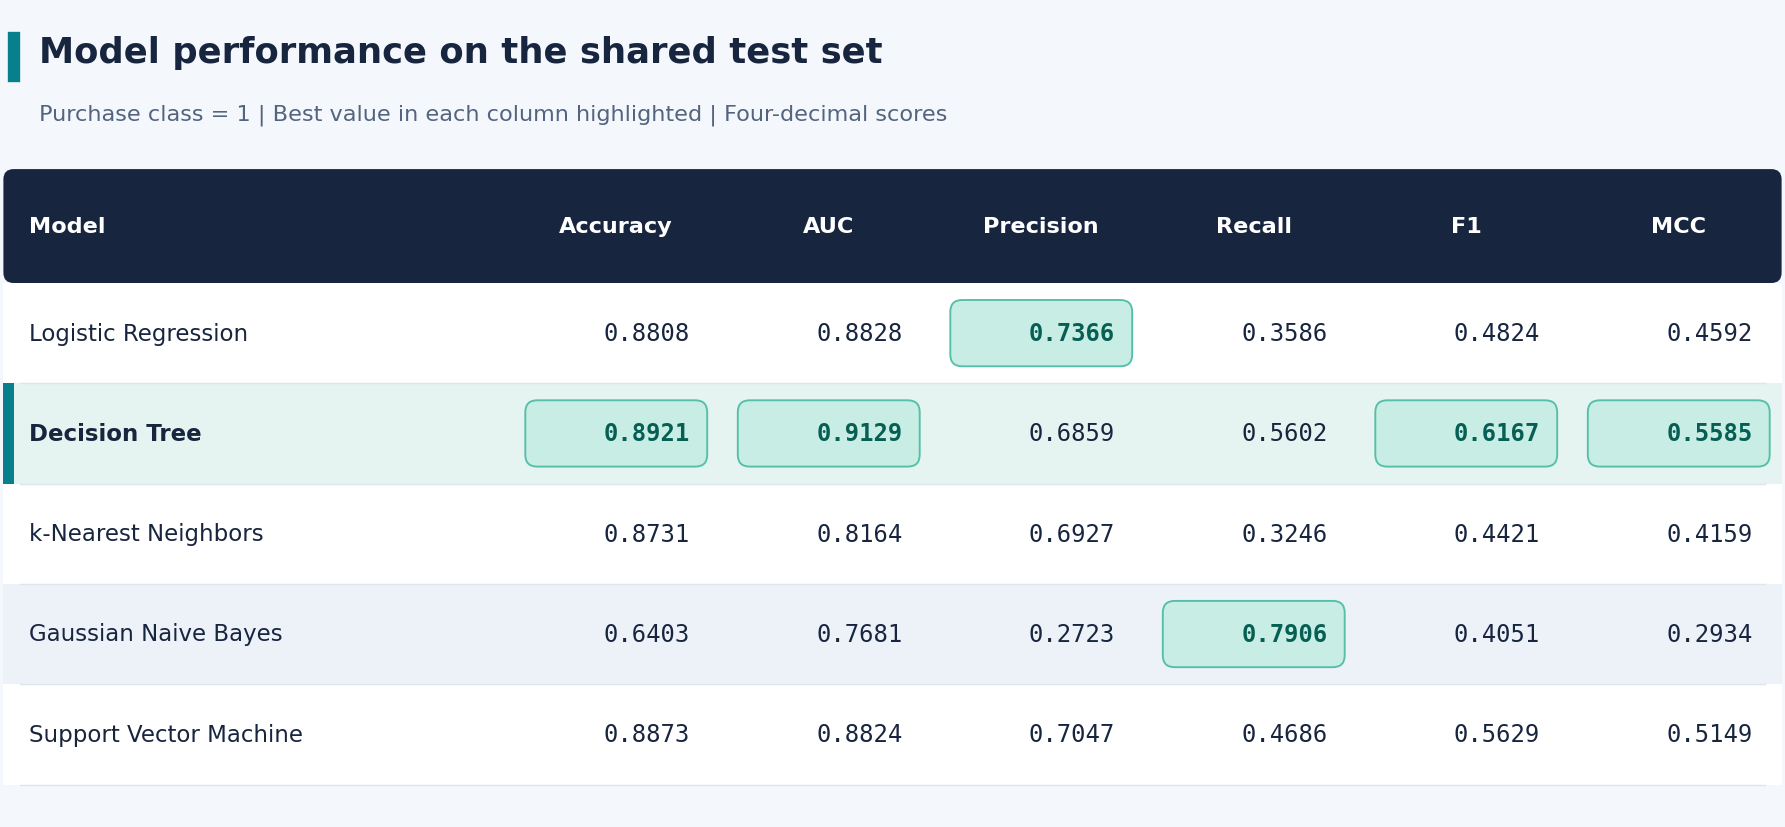

Model,Accuracy,AUC,Precision,Recall,F1,MCC
Logistic Regression,0.8808,0.8828,0.7366,0.3586,0.4824,0.4592
Decision Tree,0.8921,0.9129,0.6859,0.5602,0.6167,0.5585
k-Nearest Neighbors,0.8731,0.8164,0.6927,0.3246,0.4421,0.4159
Gaussian Naive Bayes,0.6403,0.7681,0.2723,0.7906,0.4051,0.2934
Support Vector Machine,0.8873,0.8824,0.7047,0.4686,0.5629,0.5149


In [7]:
def purchase_score(pipeline, X):
    if hasattr(pipeline, "predict_proba"):
        positive_col = list(pipeline.classes_).index(1)
        return pipeline.predict_proba(X)[:, positive_col]
    return pipeline.decision_function(X)

metric_rows = []
matrices = {}
scores = {}
for name, pipeline in fitted.items():
    predicted = pipeline.predict(X_test)
    scores[name] = purchase_score(pipeline, X_test)
    matrices[name] = confusion_matrix(y_test, predicted, labels=[0, 1])
    metric_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predicted),
        "AUC": roc_auc_score(y_test, scores[name]),
        "Precision": precision_score(y_test, predicted, zero_division=0),
        "Recall": recall_score(y_test, predicted, zero_division=0),
        "F1": f1_score(y_test, predicted, zero_division=0),
        "MCC": matthews_corrcoef(y_test, predicted),
    })

comparison = pd.DataFrame(metric_rows).set_index("Model")
comparison.to_csv(results_dir / "model_comparison.csv")
display_table(
    comparison, "Model performance on the shared test set",
    "Purchase class = 1 | Best value in each column highlighted | Four-decimal scores",
    formats={metric: ".4f" for metric in comparison.columns},
    highlight_columns=list(comparison.columns), accent_row="Decision Tree",
)

### Comparing precision, recall, and F1 directly

I use the same score scale across models and preserve their exact scores in the table above. The chart makes the tradeoff visible: Gaussian Naive Bayes reaches more buyers, while Logistic Regression has fewer incorrect alerts. The Decision Tree achieves the highest purchase F1.

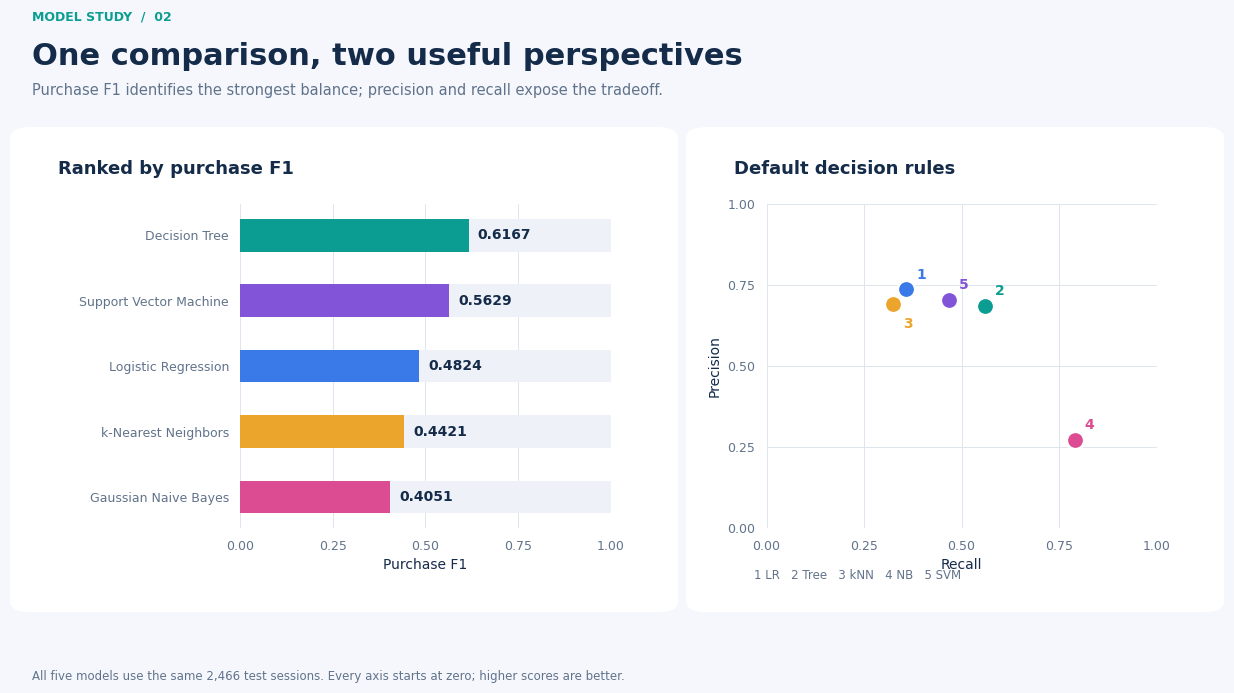

In [8]:
fig = comparison_figure(comparison)
show_figure(fig, "model_comparison.png")

### A three-dimensional view of model performance

I place each model at its **precision, recall, and MCC** coordinates. The vertical guides connect each point to the precision-recall plane, and the accompanying values allow exact comparisons. This is a view of evaluation metrics, **not the original feature space or a model decision boundary**. Perspective can change apparent distances, so I use the table and the F1-first rule for selection.

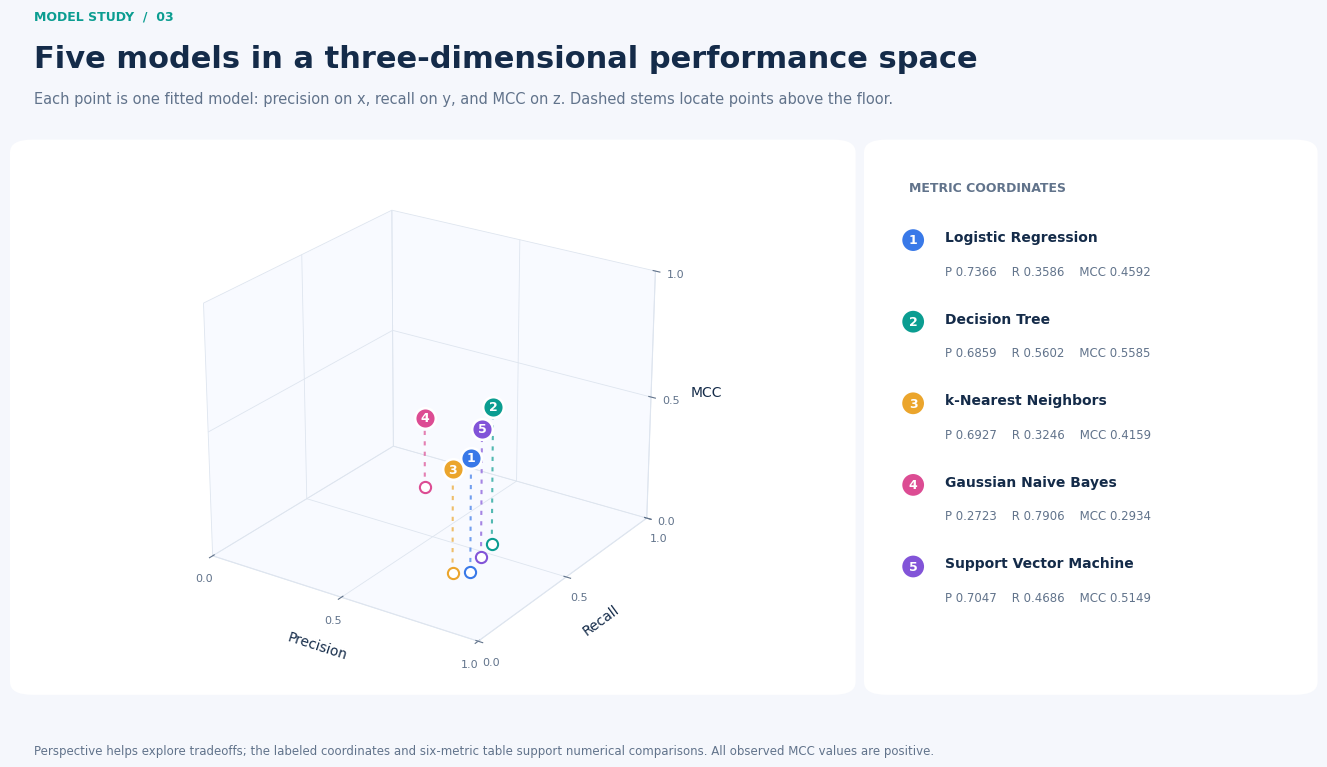

In [9]:
fig = landscape_3d_figure(comparison)
show_figure(fig, "model_landscape_3d.png")

## 6. False alarms and missed purchases

I use confusion matrices to count the two kinds of errors directly. A false alarm is a nonpurchase session that I classify as a purchase. A missed buyer is a purchase session that I classify as a nonpurchase. I use a shared color scale so that the same shade represents the same number of sessions across models.

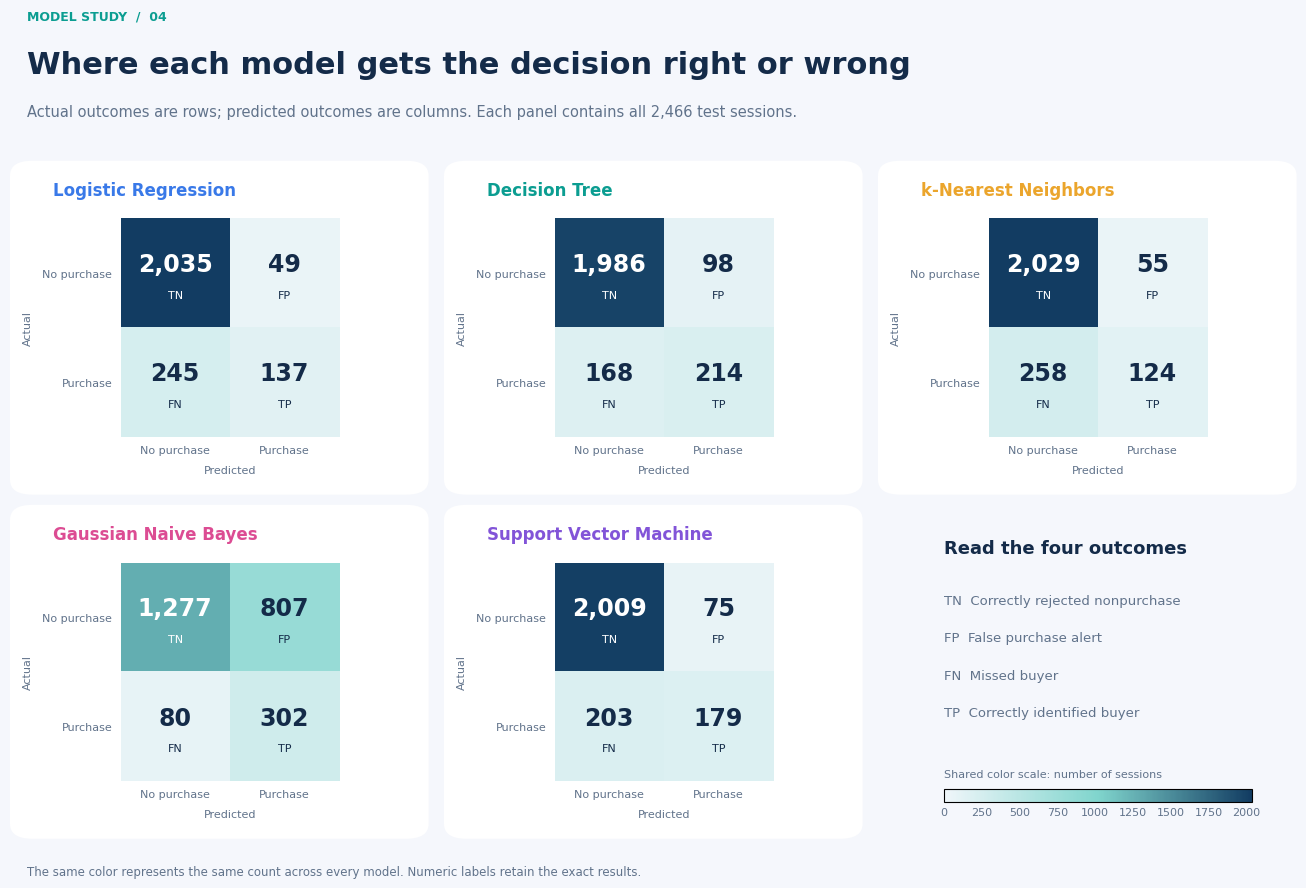

In [10]:
fig = confusion_figure(matrices)
show_figure(fig, "confusion_matrices.png")

### The same confusion counts as three-dimensional bars

I use bar height to represent session counts, with one shared vertical scale across all five panels. The four outcome colors remain fixed across models, and every bar has an exact count. The flat matrices above provide a second view when perspective makes a small bar harder to compare.

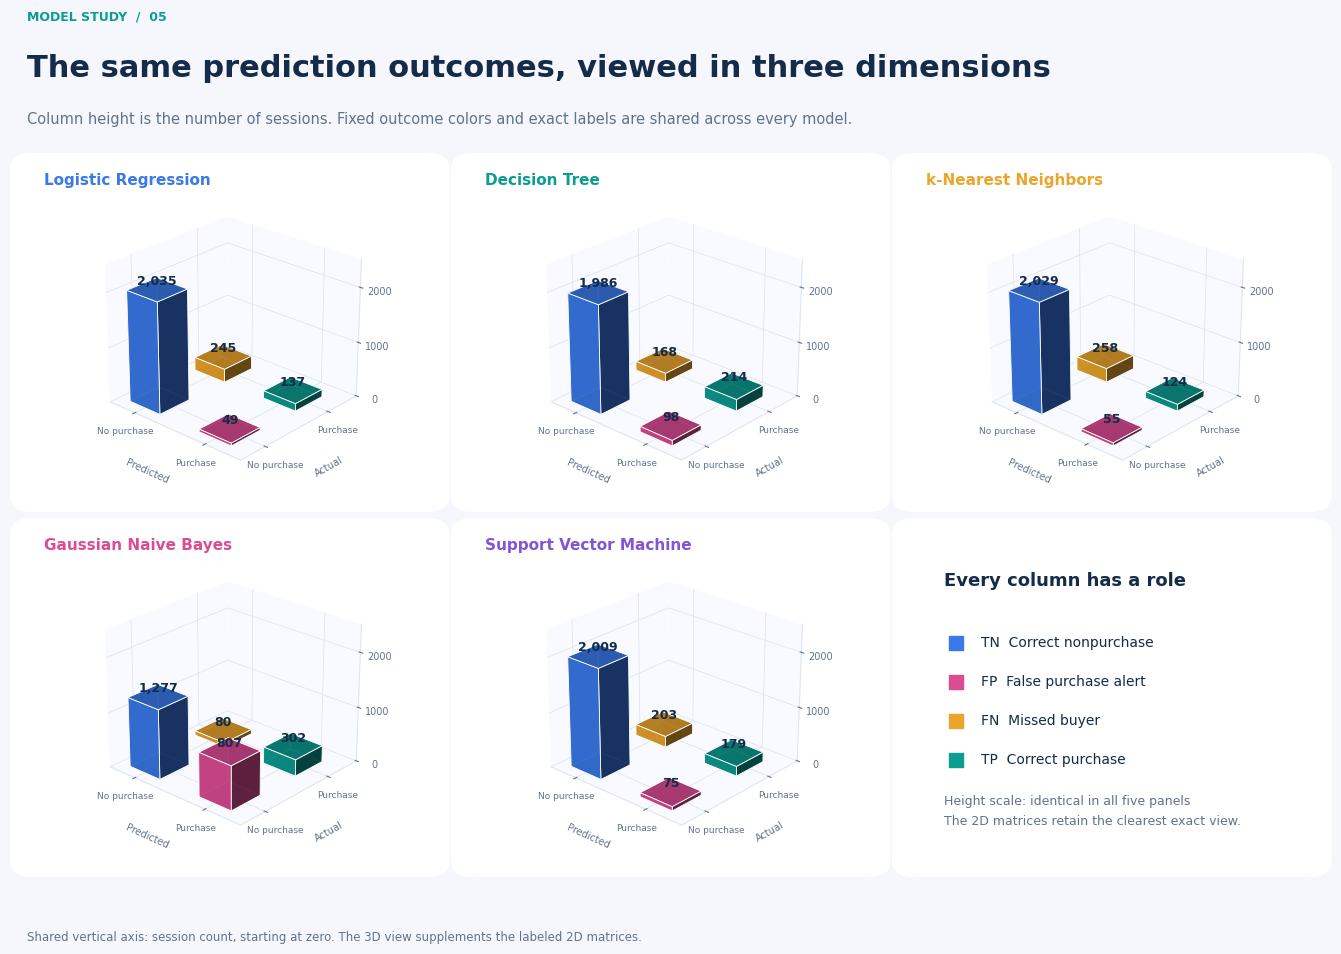

In [11]:
fig = confusion_3d_figure(matrices)
show_figure(fig, "confusion_matrices_3d.png")

### Ranking buyers across thresholds

I plot the true positive rate against the false positive rate as the threshold varies. The diagonal represents chance ranking. The ROC curves let me compare model rankings independently of how many visits each model flags at its default threshold.

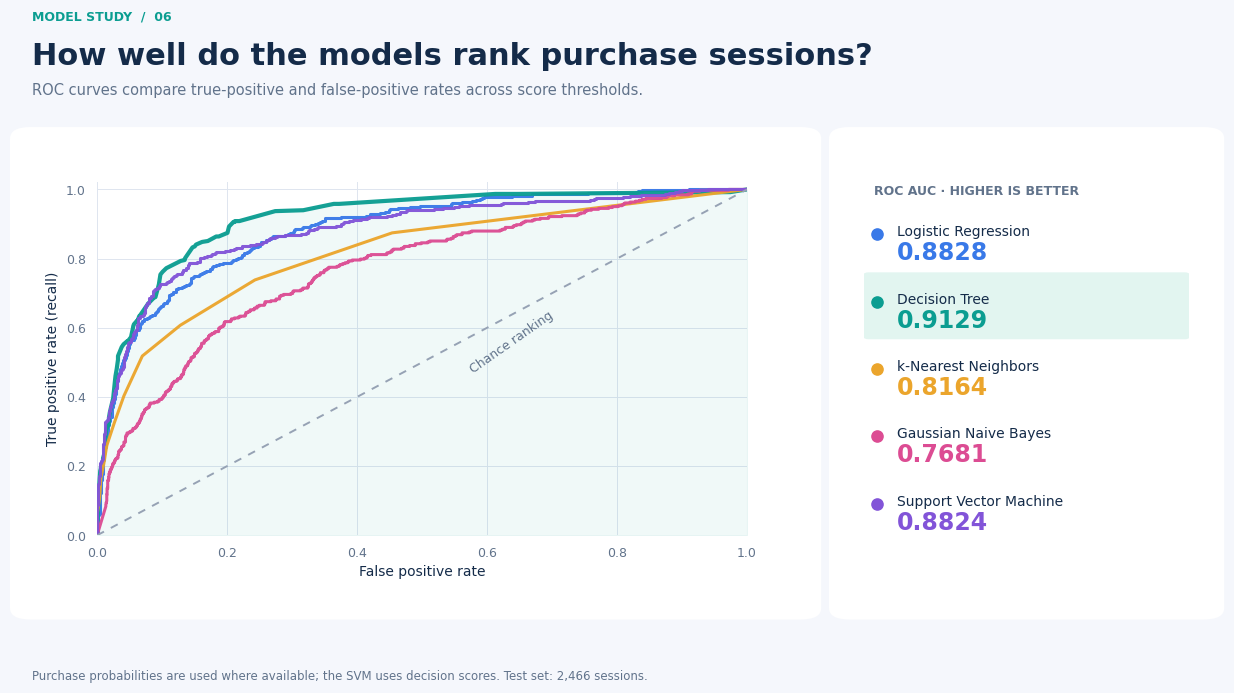

In [12]:
fig = roc_figure(y_test, scores, comparison)
show_figure(fig, "roc_curves.png")

### Precision-recall curves for the minority purchase class

I add precision-recall curves to show how the reliability of purchase alerts changes as more buyers are included. The reference is the test purchase proportion, **382 / 2,466 = 15.49%**. **Average precision (AP)** summarizes each model's precision-recall behavior; it is a supplemental measure and leaves the six required metrics unchanged.

The Decision Tree has the highest AP (**0.6763**), with the SVM close behind (**0.6689**). These curves describe ranking across thresholds, whereas the original precision, recall, and F1 table uses each model's default decision rule. I have not selected or tuned a new threshold from the test set.

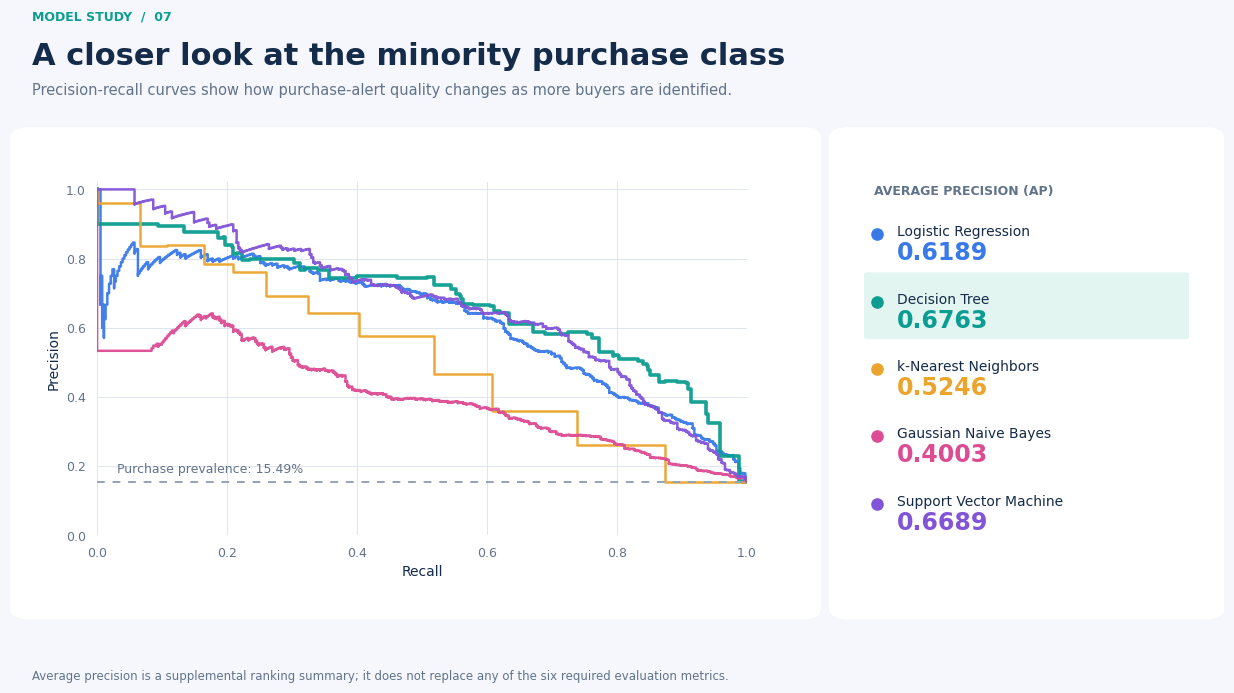

In [13]:
fig = precision_recall_figure(y_test, scores)
show_figure(fig, "precision_recall_curves.png")

## 7. Model observations

I group the buyer counts and false alarms with precision, recall and F1. I rank the models by purchase F1, using MCC if two models have the same F1.

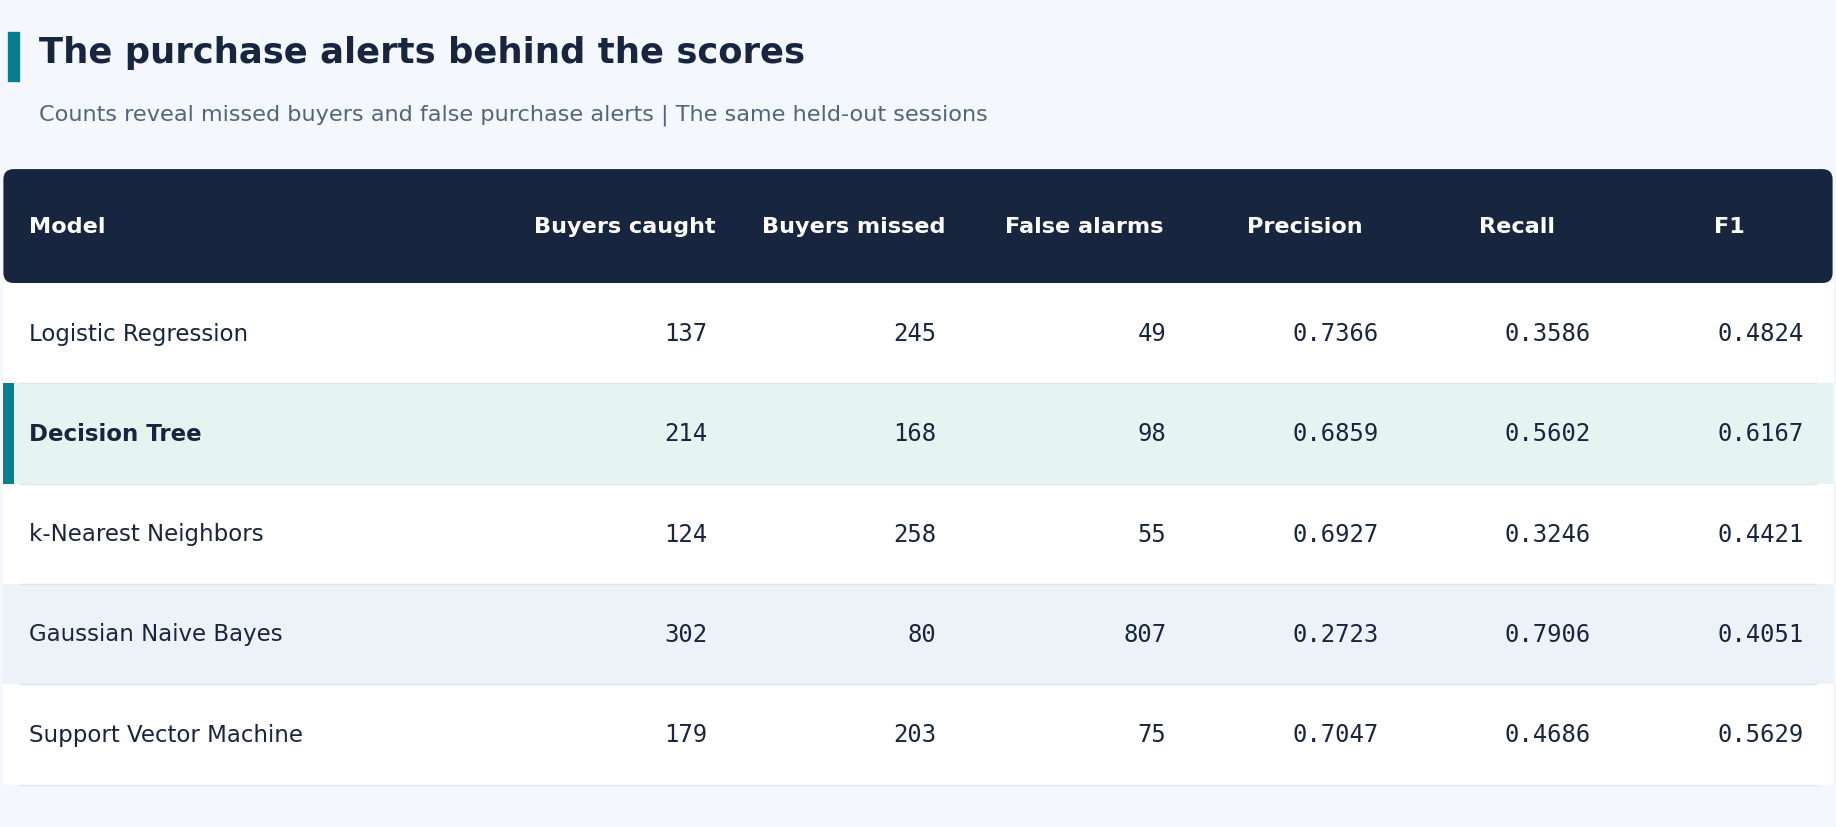

Model,Buyers caught,Buyers missed,False alarms,Precision,Recall,F1
Logistic Regression,137,245,49,0.7366,0.3586,0.4824
Decision Tree,214,168,98,0.6859,0.5602,0.6167
k-Nearest Neighbors,124,258,55,0.6927,0.3246,0.4421
Gaussian Naive Bayes,302,80,807,0.2723,0.7906,0.4051
Support Vector Machine,179,203,75,0.7047,0.4686,0.5629


Highest-ranked model by the stated rule: Decision Tree
F1 = 0.6167 | MCC = 0.5585


In [14]:
evidence = []
for name, matrix in matrices.items():
    tn, fp, fn, tp = matrix.ravel()
    evidence.append({
        "Model": name, "Buyers caught": tp, "Buyers missed": fn, "False alarms": fp,
    })
error_table = pd.DataFrame(evidence).set_index("Model")
evidence_table = error_table.join(comparison[["Precision", "Recall", "F1"]])
display_table(
    evidence_table, "The purchase alerts behind the scores",
    "Counts reveal missed buyers and false purchase alerts | The same held-out sessions",
    formats={"Buyers caught": ",.0f", "Buyers missed": ",.0f", "False alarms": ",.0f",
             "Precision": ".4f", "Recall": ".4f", "F1": ".4f"},
    widths=[3.0, 1.35, 1.35, 1.35, 1.25, 1.25, 1.25], accent_row="Decision Tree",
)
ranking = comparison.sort_values(["F1", "MCC"], ascending=False)
winner = ranking.index[0]
print(f"Highest-ranked model by the stated rule: {winner}")
print(f"F1 = {ranking.iloc[0]['F1']:.4f} | MCC = {ranking.iloc[0]['MCC']:.4f}")

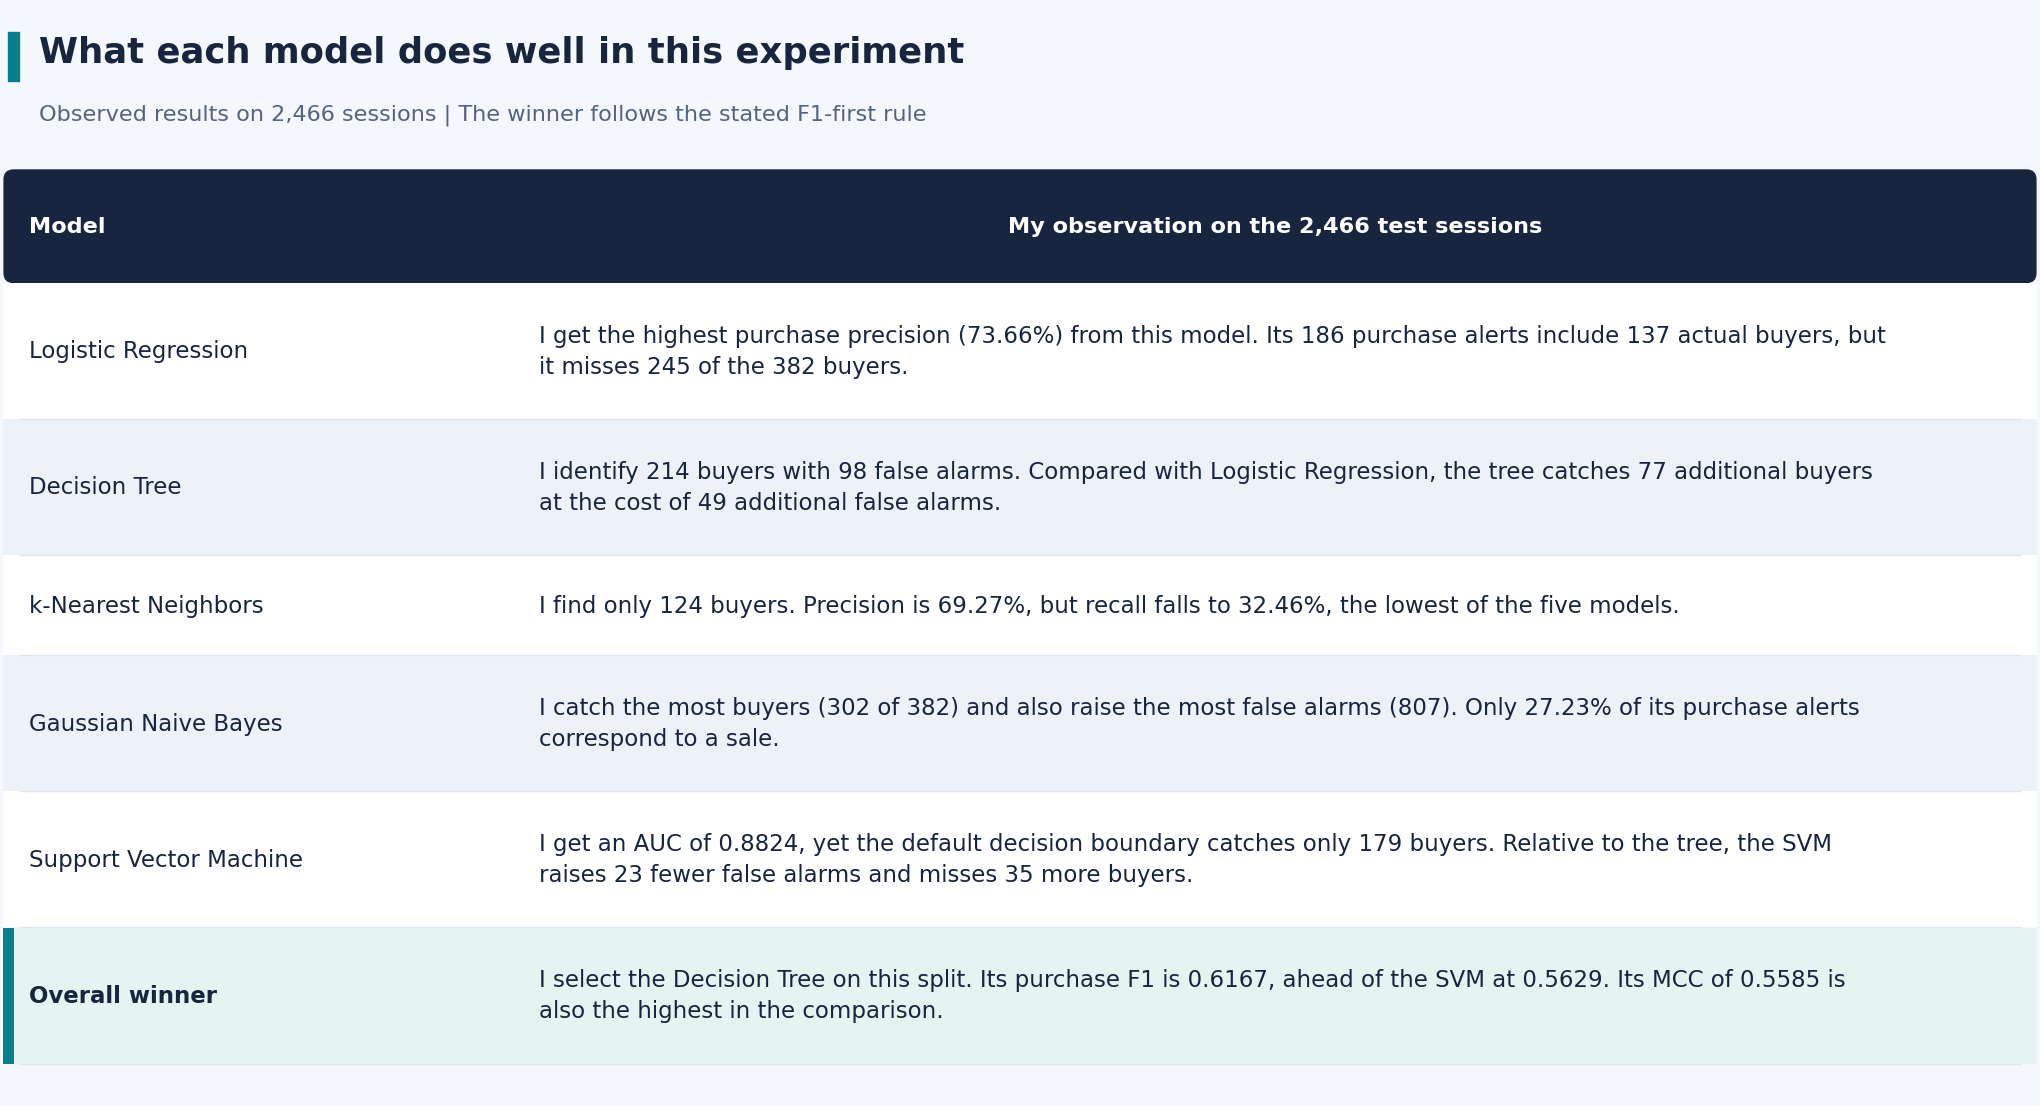

Model,"My observation on the 2,466 test sessions"
Logistic Regression,"I get the highest purchase precision (73.66%) from this model. Its 186 purchase alerts include 137 actual buyers, but it misses 245 of the 382 buyers."
Decision Tree,"I identify 214 buyers with 98 false alarms. Compared with Logistic Regression, the tree catches 77 additional buyers at the cost of 49 additional false alarms."
k-Nearest Neighbors,"I find only 124 buyers. Precision is 69.27%, but recall falls to 32.46%, the lowest of the five models."
Gaussian Naive Bayes,I catch the most buyers (302 of 382) and also raise the most false alarms (807). Only 27.23% of its purchase alerts correspond to a sale.
Support Vector Machine,"I get an AUC of 0.8824, yet the default decision boundary catches only 179 buyers. Relative to the tree, the SVM raises 23 fewer false alarms and misses 35 more buyers."
Overall winner,"I select the Decision Tree on this split. Its purchase F1 is 0.6167, ahead of the SVM at 0.5629. Its MCC of 0.5585 is also the highest in the comparison."


In [15]:
observation_table = pd.DataFrame([['Logistic Regression', 'I get the highest purchase precision (73.66%) from this model. Its 186 purchase alerts include 137 actual buyers, but it misses 245 of the 382 buyers.'], ['Decision Tree', 'I identify 214 buyers with 98 false alarms. Compared with Logistic Regression, the tree catches 77 additional buyers at the cost of 49 additional false alarms.'], ['k-Nearest Neighbors', 'I find only 124 buyers. Precision is 69.27%, but recall falls to 32.46%, the lowest of the five models.'], ['Gaussian Naive Bayes', 'I catch the most buyers (302 of 382) and also raise the most false alarms (807). Only 27.23% of its purchase alerts correspond to a sale.'], ['Support Vector Machine', 'I get an AUC of 0.8824, yet the default decision boundary catches only 179 buyers. Relative to the tree, the SVM raises 23 fewer false alarms and misses 35 more buyers.'], ['Overall winner', 'I select the Decision Tree on this split. Its purchase F1 is 0.6167, ahead of the SVM at 0.5629. Its MCC of 0.5585 is also the highest in the comparison.']], columns=['Model', 'My observation on the 2,466 test sessions']).set_index("Model")
display_table(observation_table, "What each model does well in this experiment",
              "Observed results on 2,466 sessions | The winner follows the stated F1-first rule",
              widths=[3.0, 9.0], accent_row="Overall winner")

### Logistic Regression: the most precise alert set

I get the cleanest set of purchase alerts from Logistic Regression: **137 of 186 alerts are correct**, giving **73.66% precision**, the highest of the five models. Its **49 false alerts** are also the fewest. This behavior is useful when following up on an incorrect purchase prediction is costly, although the model misses **245 of 382 buyers**.

I use its linear decision boundary as a reference. My results suggest that this configuration is conservative about identifying the minority purchase class. I would investigate alternative thresholds within training-data validation before deciding whether its low recall is acceptable.

### Decision Tree: the strongest balance under my selection rule

I select the Decision Tree because it leads on **F1 (0.6167)**, **MCC (0.5585)**, and **ROC AUC (0.9129)**. It catches **214 buyers**, which is **77 more than Logistic Regression**, while producing **49 additional false alerts**.

The tree can represent feature thresholds and interactions. I interpret its results as consistent with that flexibility helping on these sessions, although this experiment does not isolate the reason for the improvement. Restricting depth to seven and requiring 15 samples per leaf limits complexity; neither setting establishes that overfitting has been eliminated.

### k-Nearest Neighbors: reasonable precision with limited buyer coverage

I obtain **69.27% precision** from k-Nearest Neighbors, but it identifies only **124 buyers**. Its **32.46% recall** is the lowest of the five models. It produces relatively few false alerts (**55**), yet misses **258 purchases**, so its **87.31% accuracy** gives an incomplete picture of its usefulness.

After preprocessing, each session has **75 numerical coordinates**, including encoded categories. Distances in this representation and the majority of nonpurchase sessions may influence the 11-neighbor vote. I treat this as a plausible explanation to investigate, rather than a demonstrated cause. Alternative distance settings and neighbor counts would require training-data validation.

### Gaussian Naive Bayes: the broadest buyer coverage

I identify the most buyers with Gaussian Naive Bayes: **302 of 382**, or **79.06% recall**. This is **88 more buyers than the Decision Tree**, but it comes with **709 additional false alerts**. Its **27.23% precision** means that most purchase alerts are incorrect.

This model could be useful for broad screening when missed buyers matter more than the cost of reviewing false alerts. Its Gaussian and conditional-independence assumptions are imperfect matches for encoded categories and potentially related browsing measures. I regard those assumptions as possible contributors to its behavior; this experiment does not establish that they explain the errors.

### Support Vector Machine: a competitive compromise

I obtain the second-highest **F1 (0.5629)** and **MCC (0.5149)** from the SVM. It catches **179 buyers** with **75 false alerts**. Compared with the Decision Tree, it sacrifices **35 detected buyers** to avoid **23 false alerts**, while achieving higher precision (**70.47% versus 68.59%**).

Its radial basis function kernel allows a nonlinear decision boundary, but that flexibility does not guarantee the best result. I would consider it when somewhat fewer false alerts justify reduced buyer coverage. Its decision scores support ranking and ROC analysis; I do not interpret those scores as calibrated purchase probabilities.

### Matching the model to the intended use

I prefer the **Decision Tree** for a balance between purchase precision and recall under my F1-first rule. I would consider **Logistic Regression** for a smaller, more precise alert set, **Gaussian Naive Bayes** for broader buyer screening, and the **SVM** for a compromise with fewer false alerts than the tree. The current **kNN** configuration offers no leading metric in this comparison.

These are conditional choices from one shared test split. A stronger selection process would compare configurations within the training data, account for the costs of both error types, and use an untouched final test set.

## 8. Saved models and reproducibility

I save each fitted classifier together with its preprocessing steps so that the same transformations apply to new sessions. I reload all five pipelines and evaluate them on the exported `test_data.csv`. For each reloaded model, I compare its confusion matrix and AUC against the original calculation. I record the package versions used in the run.

In [16]:
loaded_test = pd.read_csv(root / "test_data.csv")
app_X = loaded_test.drop(columns=TARGET)
app_y = purchase_labels(loaded_test[TARGET])
np.testing.assert_array_equal(app_y, y_test)

for name, pipeline in fitted.items():
    slug = name.lower().replace("-", "_").replace(" ", "_")
    model_file = model_dir / f"{slug}.joblib"
    joblib.dump(pipeline, model_file, compress=3)
    restored = joblib.load(model_file)
    predictions = restored.predict(app_X)
    np.testing.assert_array_equal(predictions, pipeline.predict(X_test))
    np.testing.assert_allclose(purchase_score(restored, app_X), scores[name], atol=1e-10, rtol=1e-10)
    restored_auc = roc_auc_score(app_y, purchase_score(restored, app_X))
    np.testing.assert_array_equal(
        confusion_matrix(app_y, predictions, labels=[0, 1]), matrices[name]
    )
    np.testing.assert_allclose(restored_auc, comparison.loc[name, "AUC"], atol=1e-6)
    print(f"Verified model/{model_file.name}")

packages = ["scikit-learn", "numpy", "pandas", "scipy", "joblib", "matplotlib", "threadpoolctl"]
versions = [f"{package}=={version(package)}" for package in packages]
(results_dir / "training_versions.txt").write_text(chr(10).join(versions) + chr(10), encoding="utf-8", newline="\n")
print("Saved results/training_versions.txt")

Verified model/logistic_regression.joblib
Verified model/decision_tree.joblib


Verified model/k_nearest_neighbors.joblib
Verified model/gaussian_naive_bayes.joblib


Verified model/support_vector_machine.joblib
Saved results/training_versions.txt


## Conclusion

For a balance between catching buyers and keeping false alerts manageable, I would use the Decision Tree. It detects 56.02% of purchase sessions on the held-out data. If catching almost four out of five buyers mattered more than the number of false alerts, my results would favor Gaussian Naive Bayes instead.

My comparison covers a single stratified split. The inputs describe activity accumulated during a visit, including time on product pages. I would evaluate features available at a specific point in a live session before using these results to make an earlier prediction.

### References

1. C. Sakar and Y. Kastro (2018). *Online Shoppers Purchasing Intention Dataset*. UCI Machine Learning Repository. [Dataset and attribution](https://doi.org/10.24432/C5F88Q) · [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/)
2. Scikit-learn documentation. [Pipelines and composite estimators](https://scikit-learn.org/stable/modules/compose.html) · [Classification metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics)

The source contains 125 duplicate rows beyond their first occurrences. I retain them to preserve this experiment and report cross-split feature overlap in `results/data_quality.json`. I use the test results to compare these five fixed configurations; a separate validation process and untouched final test set would be needed for a stronger model-selection assessment.
